# Stock Price Prediction Using Deep Learning: LSTM and GRU Models
### MBA in Data Science & Artificial Intelligence | Academic & Portfolio Capstone Project
**Author:** Aryan Koundal  
**Asset Examined:** ADANIPORTS (Adani Ports and Special Economic Zone Ltd.)  
**Primary Objective:** End-to-end time-series deep learning regression forecasting the **Next Trading Day Close Price** ($Close_{t+1}$) using a **60-day sliding window** with zero data leakage.


## 1. Environment Setup & Deterministic Reproducibility
We fix global seeds across Python, NumPy, and TensorFlow to guarantee 100% reproducible numerical and gating convergence across runs.


In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, GRU, Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print(f"TensorFlow Version : {tf.__version__}")
print(f"Pandas Version     : {pd.__version__}")
print(f"NumPy Version      : {np.__version__}")


TensorFlow Version : 2.21.0
Pandas Version     : 2.3.3
NumPy Version      : 2.3.3


## 2. Dataset Ingestion & Schema Audit
We load `ADANIPORTS-selected-columns-2.csv` containing 3,322 historical daily trading quotes from 2007 to 2021 without hardcoding column indices.


In [2]:
DATA_PATH = os.path.join("..", "data", "ADANIPORTS-selected-columns-2.csv")
df = pd.read_csv(DATA_PATH)
print("Dataset Shape:", df.shape)
print("Detected Columns:", df.columns.tolist())
df.head(5)


Dataset Shape: (3322, 10)
Detected Columns: ['Date', 'Symbol', 'Series', 'Prev Close', 'Open', 'High', 'Low', 'Last', 'Close', 'VWAP']


,Date,Symbol,Series,Prev Close,Open,High,Low,Last,Close,VWAP
0,2007-11-27,MUNDRAPORT,EQ,440.00,770.00,1050.00,770.0,959.0,962.90,984.72
1,2007-11-28,MUNDRAPORT,EQ,962.90,984.00,990.00,874.0,885.0,893.90,941.38
2,2007-11-29,MUNDRAPORT,EQ,893.90,909.00,914.75,841.0,887.0,884.20,888.09
3,2007-11-30,MUNDRAPORT,EQ,884.20,890.00,958.00,890.0,929.0,921.55,929.17
4,2007-12-03,MUNDRAPORT,EQ,921.55,939.75,995.00,922.0,980.0,969.30,965.65


## 3. Data Preprocessing & Validation
Steps:
1. Parse `Date` column to standard datetime.
2. Sort chronologically in ascending order.
3. Validate and impute missing values (forward fill + backward fill).
4. Verify price integrity ($Close > 0$ and $High \ge Low$).


In [3]:
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
df = df.dropna(subset=['Date']).sort_values(by='Date', ascending=True).reset_index(drop=True)

numeric_cols = ['Prev Close', 'Open', 'High', 'Low', 'Last', 'Close', 'VWAP']
for c in numeric_cols:
    if c in df.columns:
        df[c] = pd.to_numeric(df[c], errors='coerce')
df[numeric_cols] = df[numeric_cols].ffill().bfill()

print(f"Total Usable Records  : {len(df)}")
print(f"Chronological Range   : {df['Date'].min().strftime('%Y-%m-%d')} to {df['Date'].max().strftime('%Y-%m-%d')}")
print(f"Duplicate Timestamps  : {df['Date'].duplicated().sum()}")
print(f"Missing Values Check  :\n{df[numeric_cols].isnull().sum().to_dict()}")


Total Usable Records  : 3322
Chronological Range   : 2007-11-27 to 2021-04-30
Duplicate Timestamps  : 0
Missing Values Check  : {'Prev Close': 0, 'Open': 0, 'High': 0, 'Low': 0, 'Last': 0, 'Close': 0, 'VWAP': 0}


## 4. Technical Feature Engineering (Strictly Backward-Looking)
To eliminate look-ahead bias and future data leakage, indicators are computed strictly from day $t$ backward:
- **Daily Return (%):** $(Close_t - Close_{t-1}) / Close_{t-1} 	imes 100$
- **Moving Averages:** 20-day, 50-day, and 100-day Simple Moving Averages (SMA)
- **Volatility (20d):** 20-day rolling standard deviation of daily returns
- **Price Spreads:** Intraday Range ($High - Low$) and Daily Spread ($Open - Close$)


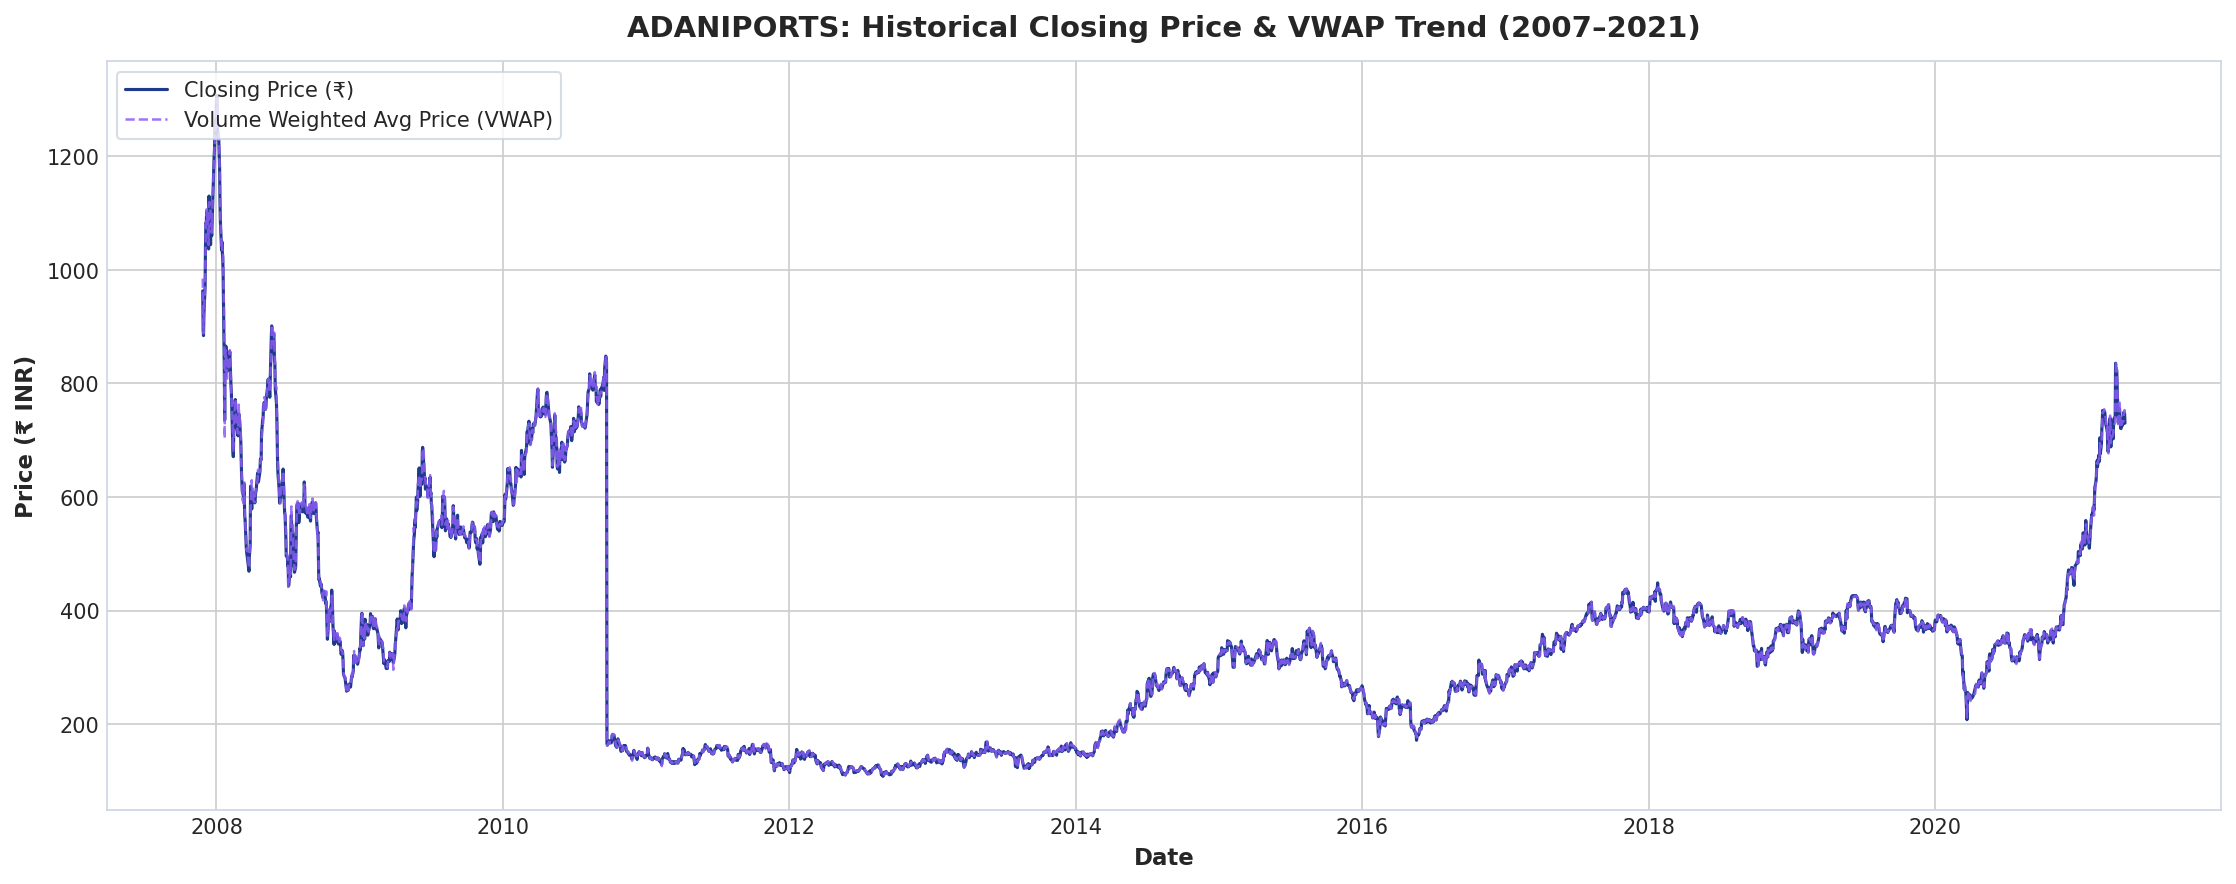

In [4]:
# Chart 1: Historical Closing Price & VWAP Trend
plt.figure(figsize=(15, 6))
plt.plot(df['Date'], df['Close'], label='Closing Price (₹)', color='#1E3A8A', lw=1.5)
plt.plot(df['Date'], df['VWAP'], label='VWAP (₹)', color='#8B5CF6', lw=1.2, linestyle='--', alpha=0.85)
plt.title('ADANIPORTS: Historical Closing Price & VWAP Trend (2007–2021)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Date', fontsize=11, fontweight='bold')
plt.ylabel('Price (₹ INR)', fontsize=11, fontweight='bold')
plt.legend(loc='upper left', frameon=True)
plt.show()


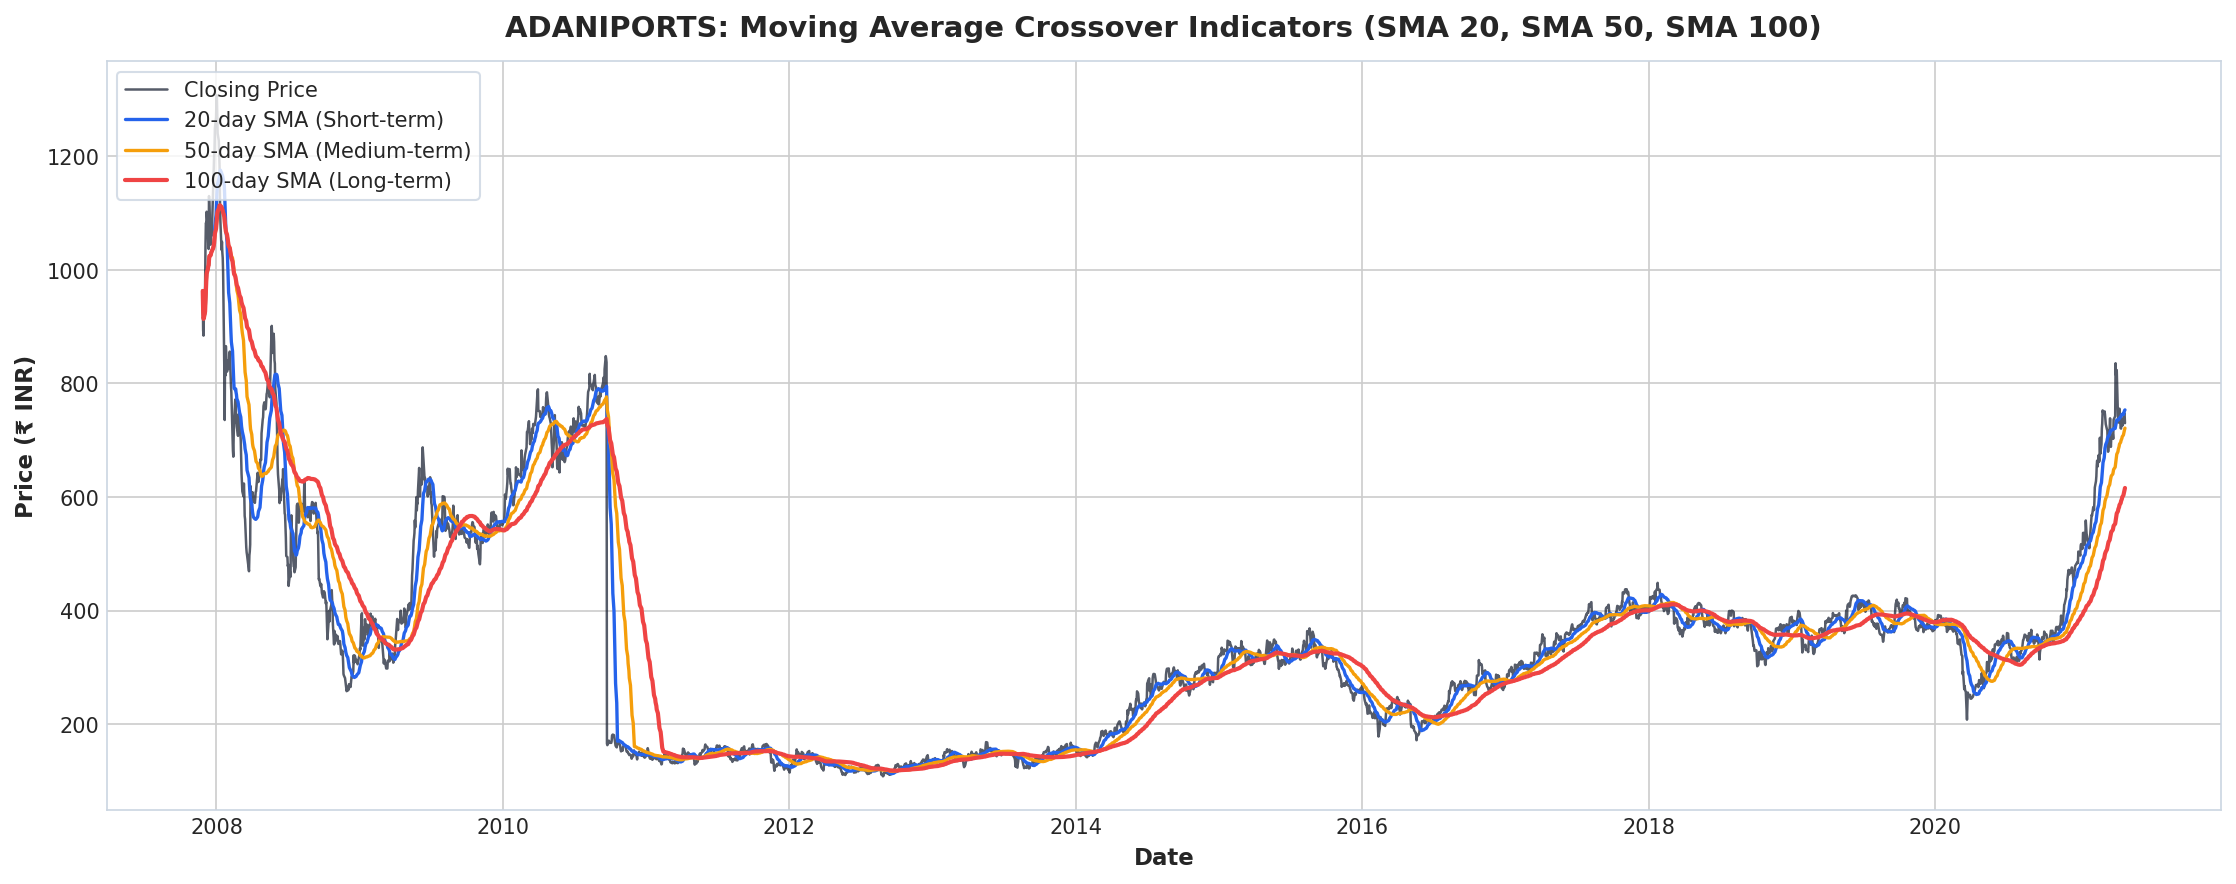

In [5]:
# Chart 2: Moving Average Trend Crossover Analysis
plt.figure(figsize=(15, 6))
plt.plot(df['Date'], df['Close'], label='Closing Price', color='#0F172A', lw=1.2, alpha=0.7)
plt.plot(df['Date'], df['SMA_20'], label='20-day SMA (Short-term)', color='#2563EB', lw=1.6)
plt.plot(df['Date'], df['SMA_50'], label='50-day SMA (Medium-term)', color='#F59E0B', lw=1.6)
plt.plot(df['Date'], df['SMA_100'], label='100-day SMA (Long-term)', color='#EF4444', lw=2.0)
plt.title('ADANIPORTS: Moving Average Crossover Indicators (SMA 20, SMA 50, SMA 100)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Date', fontsize=11, fontweight='bold')
plt.ylabel('Price (₹ INR)', fontsize=11, fontweight='bold')
plt.legend(loc='upper left', frameon=True)
plt.show()


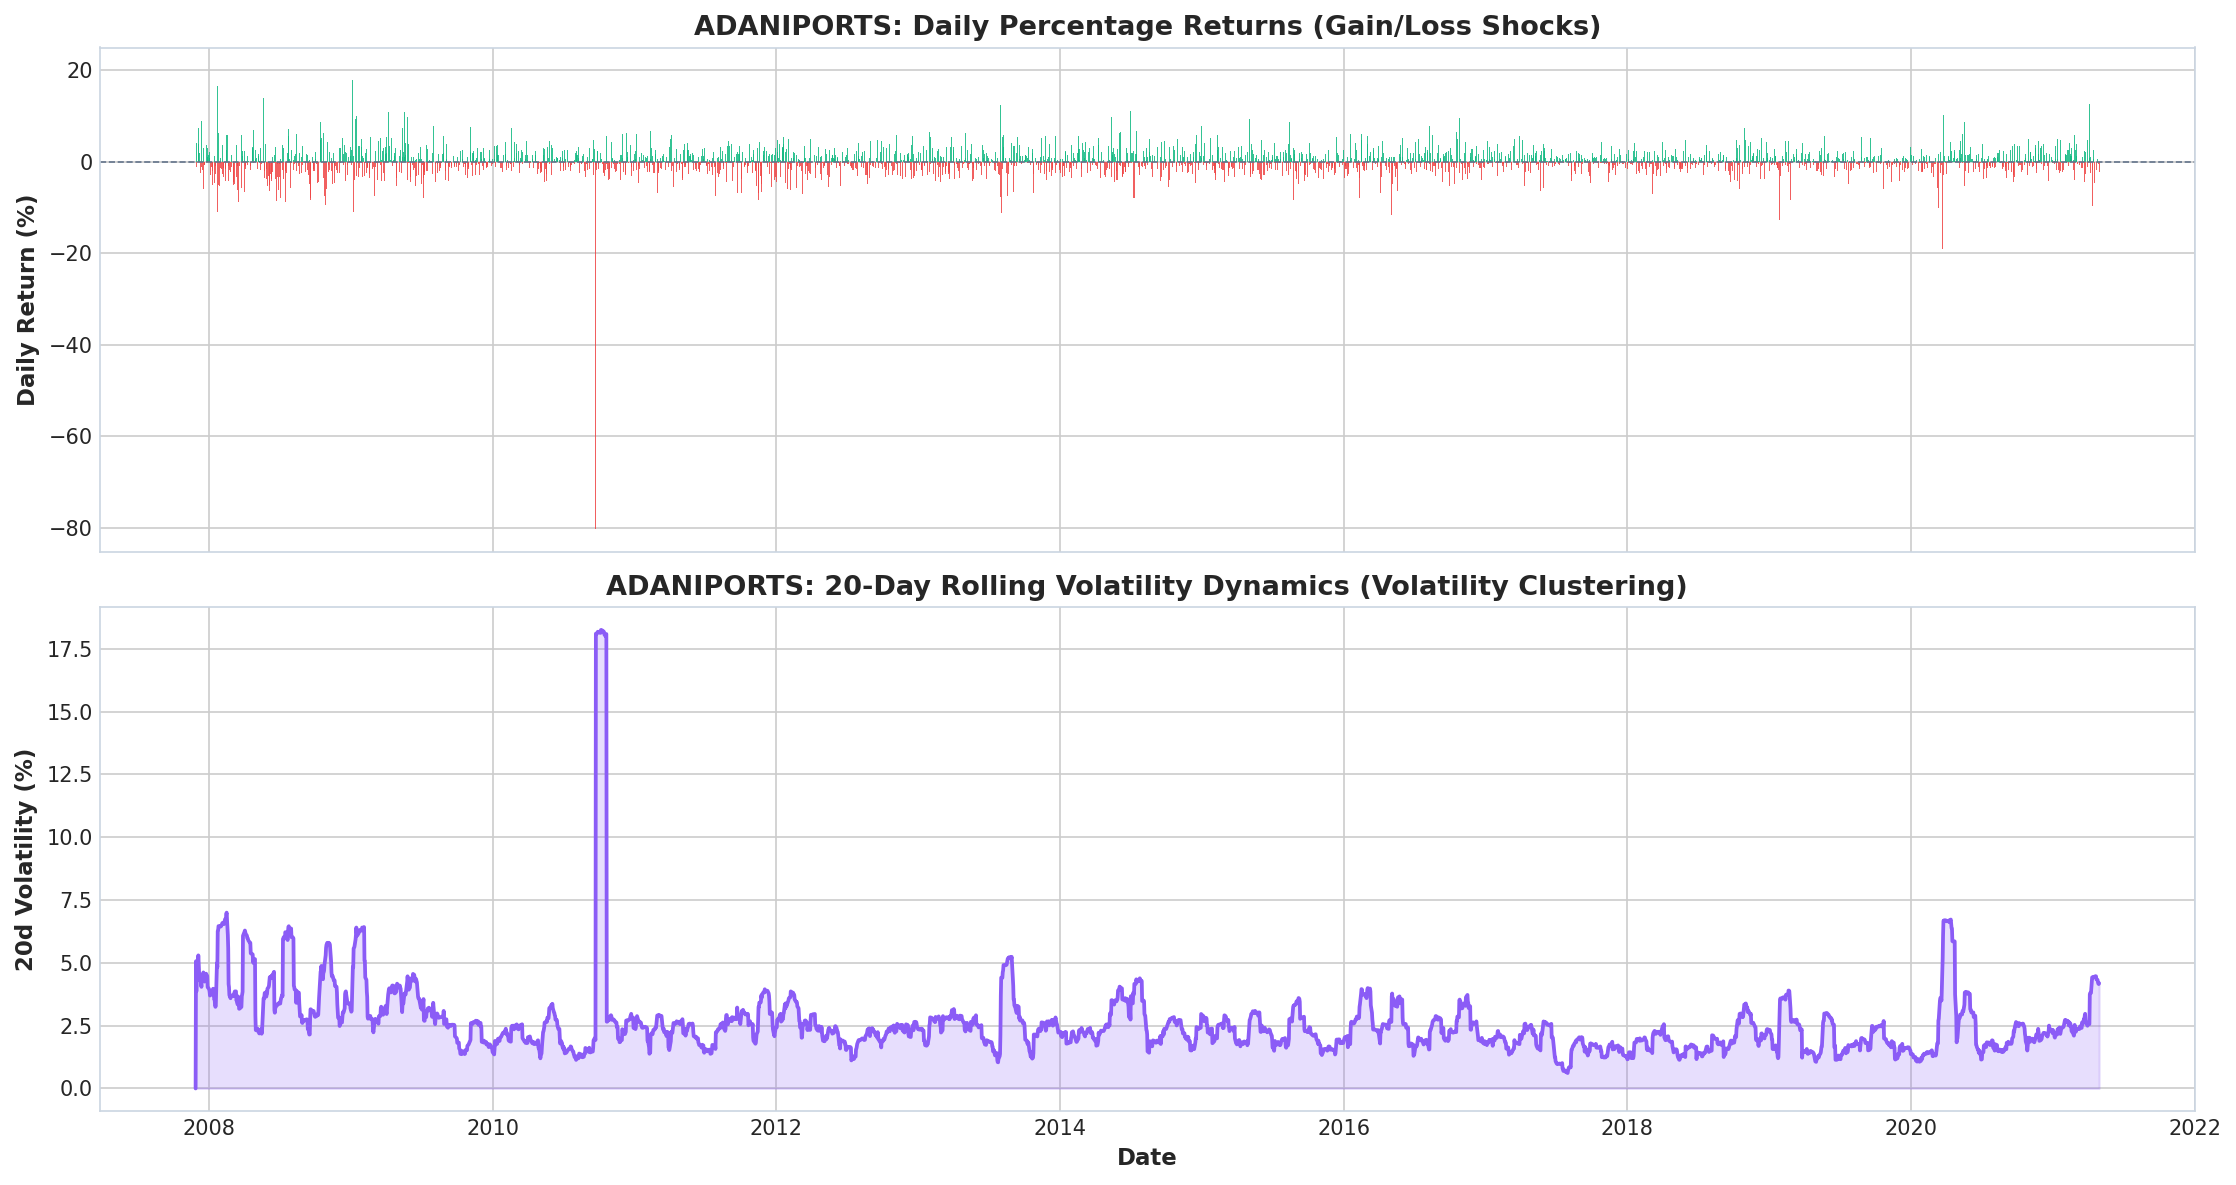

In [6]:
# Chart 3: Daily Return Shocks & Volatility Dynamics
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 8), sharex=True)
colors = ['#10B981' if r >= 0 else '#EF4444' for r in df['Daily_Return']]
ax1.bar(df['Date'], df['Daily_Return'], color=colors, width=2.0, alpha=0.85)
ax1.axhline(0, color='#64748B', linestyle='--', lw=0.8)
ax1.set_ylabel('Daily Return (%)', fontsize=11, fontweight='bold')
ax1.set_title('ADANIPORTS: Daily Percentage Returns (Gain/Loss Shocks)', fontsize=13, fontweight='bold')

ax2.plot(df['Date'], df['Volatility_20'], color='#8B5CF6', lw=1.8)
ax2.fill_between(df['Date'], 0, df['Volatility_20'], color='#8B5CF6', alpha=0.2)
ax2.set_ylabel('20d Volatility (%)', fontsize=11, fontweight='bold')
ax2.set_xlabel('Date', fontsize=11, fontweight='bold')
ax2.set_title('ADANIPORTS: 20-Day Rolling Volatility Dynamics (Volatility Clustering)', fontsize=13, fontweight='bold')
plt.show()


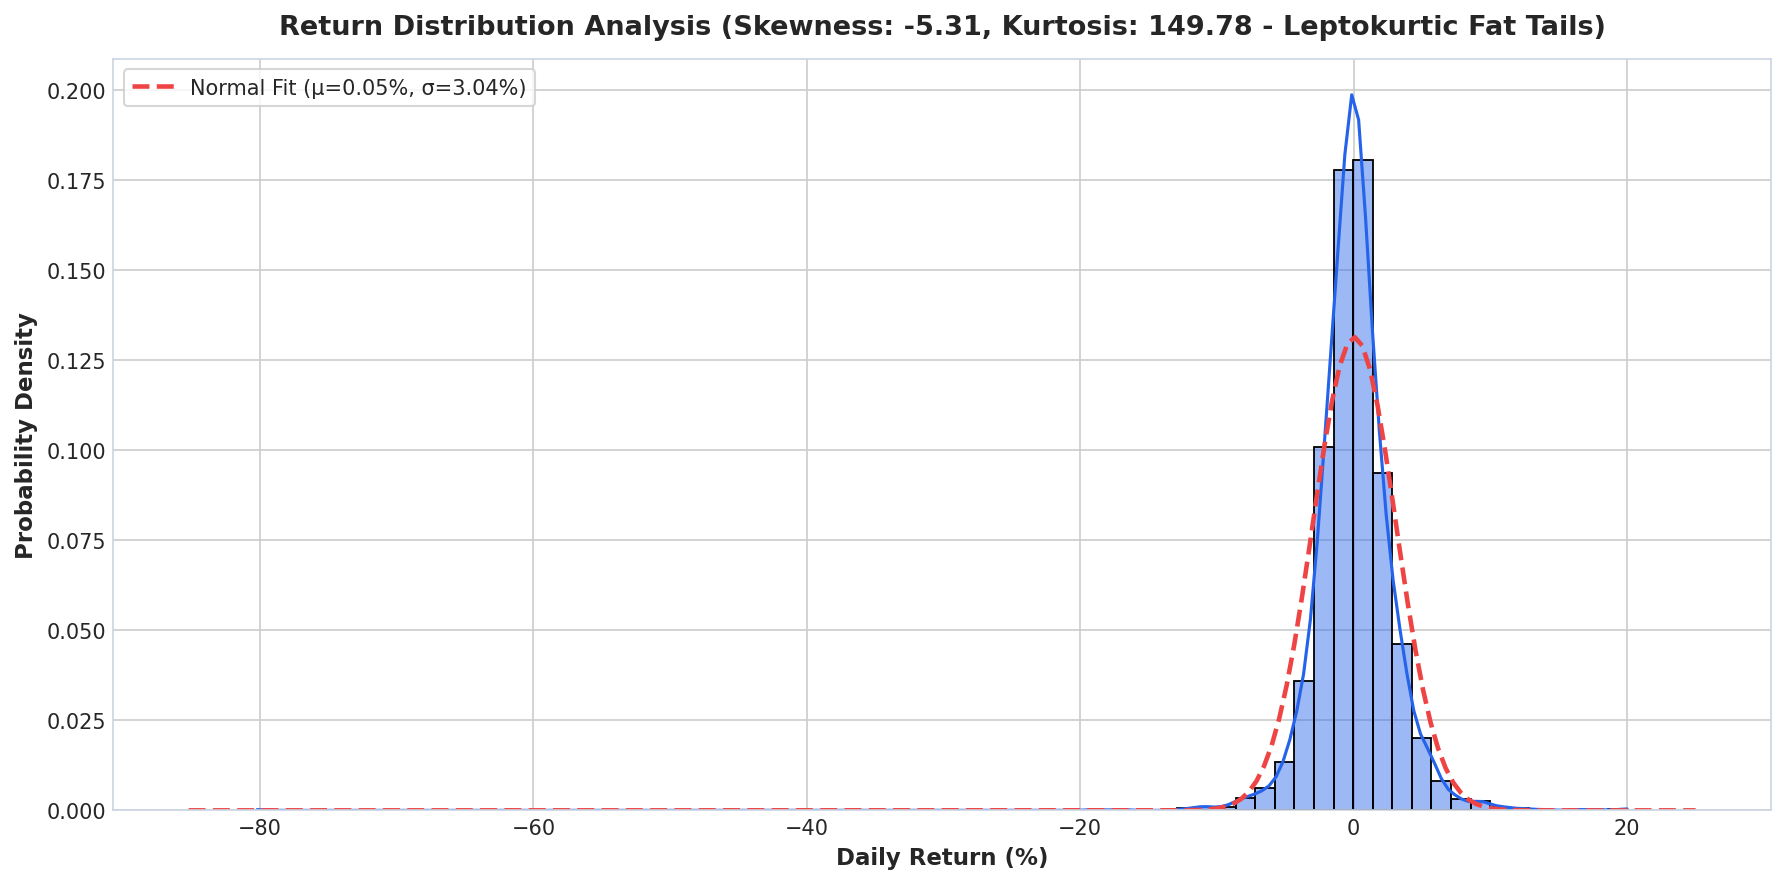

In [7]:
# Chart 4: Return Distribution & Kurtosis (Fat-Tail Risk)
plt.figure(figsize=(12, 6))
sns.histplot(df['Daily_Return'], bins=70, kde=True, color='#2563EB', stat='density', alpha=0.45)
mu, std = df['Daily_Return'].mean(), df['Daily_Return'].std()
x = np.linspace(df['Daily_Return'].min(), df['Daily_Return'].max(), 200)
p = (1 / (std * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x - mu) / std) ** 2)
plt.plot(x, p, color='#EF4444', lw=2.2, linestyle='--', label=f'Normal Curve (μ={mu:.2f}%, σ={std:.2f}%)')
plt.title(f'ADANIPORTS Return Distribution (Skewness: {df["Daily_Return"].skew():.2f}, Kurtosis: {df["Daily_Return"].kurtosis():.2f})', fontsize=13, fontweight='bold')
plt.xlabel('Daily Return (%)', fontsize=11, fontweight='bold')
plt.ylabel('Density', fontsize=11, fontweight='bold')
plt.legend()
plt.show()


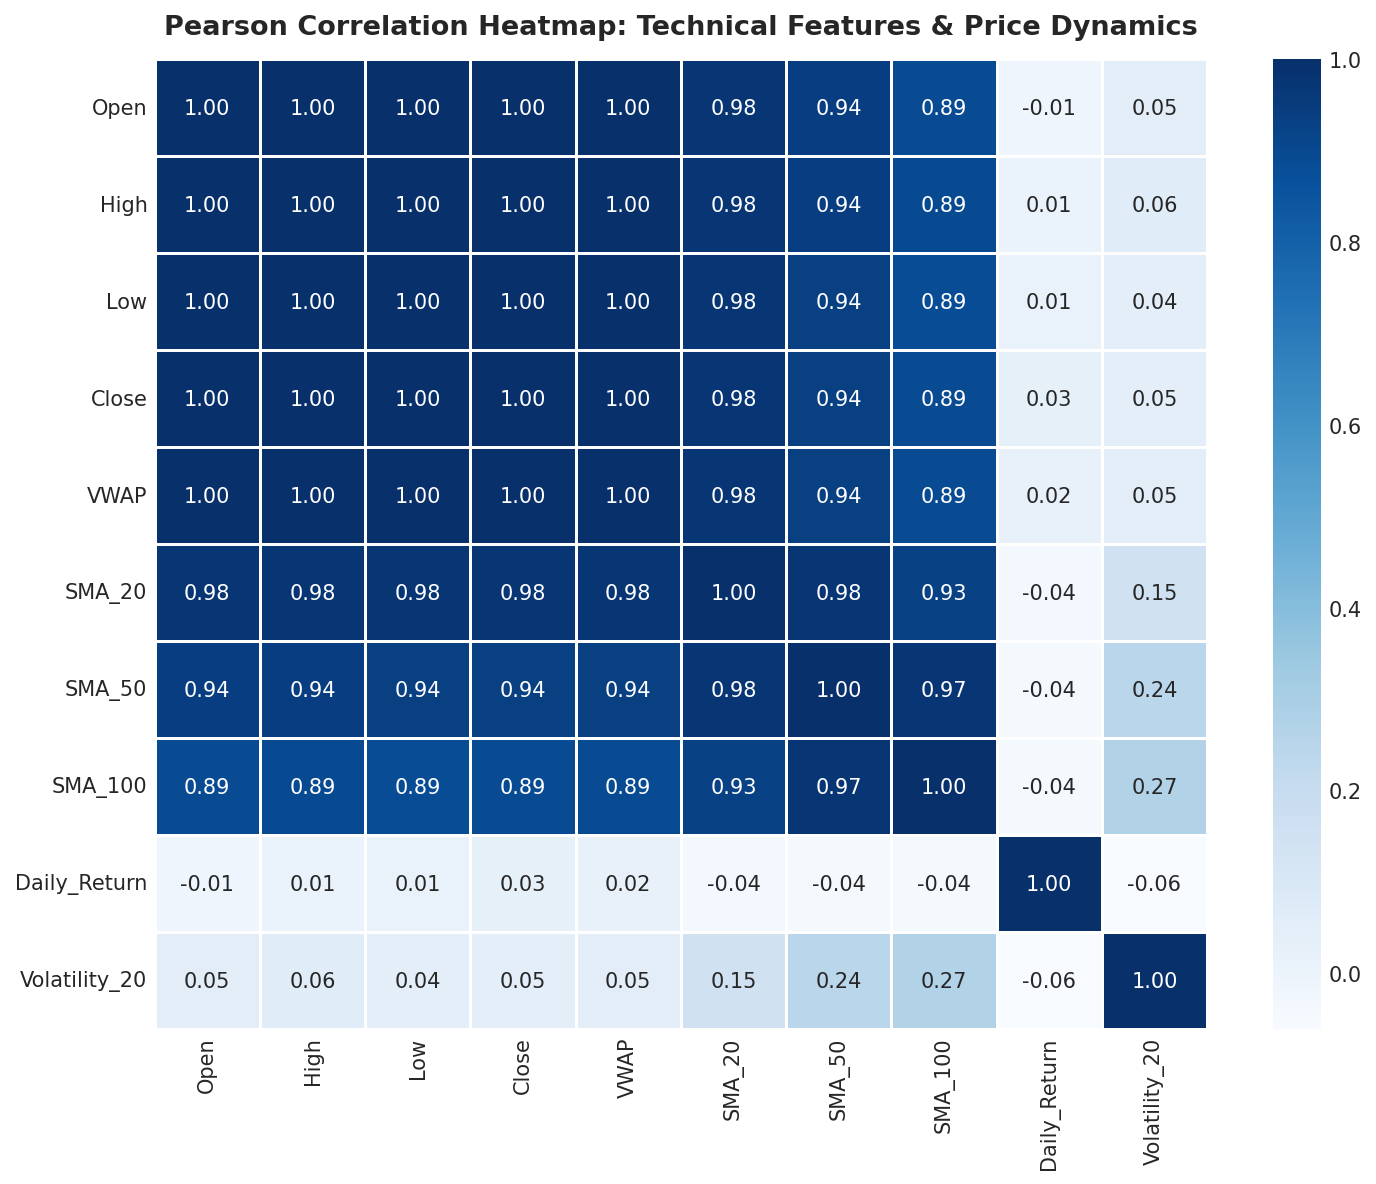

In [8]:
# Chart 5: Technical Features Correlation Heatmap
corr_cols = ['Open', 'High', 'Low', 'Close', 'VWAP', 'SMA_20', 'SMA_50', 'SMA_100', 'Daily_Return', 'Volatility_20']
plt.figure(figsize=(10, 8))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt='.2f', cmap='Blues', linewidths=0.5)
plt.title('Pearson Correlation Heatmap of Financial Indicators', fontsize=13, fontweight='bold')
plt.show()


In [9]:
# Econometric Risk & Return Metrics Summary
return_summary = pd.DataFrame({
    'Mean Daily Return (%)': [df['Daily_Return'].mean()],
    'Daily Volatility (Std Dev %)': [df['Daily_Return'].std()],
    'Max Gain (%)': [df['Daily_Return'].max()],
    'Max Drop (%)': [df['Daily_Return'].min()],
    'Skewness': [df['Daily_Return'].skew()],
    'Kurtosis': [df['Daily_Return'].kurtosis()]
}, index=['Value']).T
return_summary


,ADANIPORTS
Mean Daily Return (%),0.052552
Daily Volatility / Std (%),3.036540
Max Single-Day Surge (%),20.002177
Max Single-Day Drop (%),-80.215054
Return Skewness,-5.312609
Return Kurtosis,149.777701


## 5. Chronological Train/Test Partition & Isolated Scaling
### ZERO DATA LEAKAGE RULE:
To avoid future information bleeding into model weights:
1. First **80% of data** is assigned to training ($N=2,657$).
2. Final **20% of data** is assigned to testing ($N=665$ trading days, August 2018 to April 2021).
3. `MinMaxScaler` is fit **exclusively on the training split**. The test split is merely *transformed* with pre-fitted minimum and maximum scalars.


In [10]:
train_size = int(len(df) * 0.80)
train_df = df.iloc[:train_size].copy()
test_df = df.iloc[train_size:].copy()

# Fit scaler strictly on training data ONLY
scaler = MinMaxScaler(feature_range=(0, 1))
train_scaled = scaler.fit_transform(train_df[['Close']].values)

sequence_length = 60
test_context = df.iloc[train_size - sequence_length:][['Close']].values
test_scaled = scaler.transform(test_context)

print(f"Training Partition : {len(train_df)} days ({train_df['Date'].min().strftime('%Y-%m-%d')} to {train_df['Date'].max().strftime('%Y-%m-%d')})")
print(f"Testing Partition  : {len(test_df)} days ({test_df['Date'].min().strftime('%Y-%m-%d')} to {test_df['Date'].max().strftime('%Y-%m-%d')})")
print(f"MinMaxScaler Range : Min=₹{scaler.data_min_[0]:.2f}, Max=₹{scaler.data_max_[0]:.2f}")


Training Partition : 2657 days (2007-11-27 to 2018-08-17)
Testing Partition  : 665 days (2018-08-20 to 2021-04-30)
MinMaxScaler Range : Min=₹108.00, Max=₹1307.45


## 6. Sequence Creation (60 Trading Days Sliding Window)
Each sequence takes the previous 60 trading days ($t-59 \dots t$) as the input tensor to forecast Day $t+1$'s Close price.


In [11]:
def create_sequences(arr, seq_len=60):
    X, y = [], []
    for i in range(seq_len, len(arr)):
        X.append(arr[i-seq_len:i])
        y.append(arr[i, 0])
    return np.array(X), np.array(y)

X_train, y_train = create_sequences(train_scaled, sequence_length)
X_test, y_test = create_sequences(test_scaled, sequence_length)
y_test_unscaled = test_df['Close'].values

print("X_train Shape :", X_train.shape, "| y_train Shape :", y_train.shape)
print("X_test Shape  :", X_test.shape, "| y_test Shape  :", y_test.shape)


X_train Shape : (2597, 60, 1) | y_train Shape : (2597,)
X_test Shape  : (665, 60, 1) | y_test Shape  : (665,)


## 7. Deep Learning Architectures: LSTM vs GRU
- **Stacked LSTM (64, 32 units)** with 20% Dropout regularization and Dense layers.
- **Stacked GRU (64, 32 units)** with 20% Dropout regularization and Dense layers.
- Optimizer: **Adam ($lr=0.001$)**, Loss: **Mean Squared Error (MSE)**.


In [12]:
def build_lstm(input_shape=(60, 1)):
    model = Sequential([
        Input(shape=input_shape),
        LSTM(64, return_sequences=True, name="lstm_1"),
        Dropout(0.2, name="dropout_1"),
        LSTM(32, return_sequences=False, name="lstm_2"),
        Dropout(0.2, name="dropout_2"),
        Dense(16, activation="relu", name="dense_1"),
        Dense(1, name="output_close")
    ], name="LSTM_Predictor")
    model.compile(optimizer="adam", loss="mse", metrics=["mae"])
    return model

def build_gru(input_shape=(60, 1)):
    model = Sequential([
        Input(shape=input_shape),
        GRU(64, return_sequences=True, name="gru_1"),
        Dropout(0.2, name="dropout_1"),
        GRU(32, return_sequences=False, name="gru_2"),
        Dropout(0.2, name="dropout_2"),
        Dense(16, activation="relu", name="dense_1"),
        Dense(1, name="output_close")
    ], name="GRU_Predictor")
    model.compile(optimizer="adam", loss="mse", metrics=["mae"])
    return model

lstm_model = build_lstm()
gru_model = build_gru()
print("LSTM Architecture Summary:")
lstm_model.summary()


Model: "LSTM_Predictor"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 60, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 60, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼─────────────────

## 8. Model Training with EarlyStopping & Learning Rate Decay
We train both architectures for 30 epochs with `EarlyStopping(patience=8)` and `ReduceLROnPlateau(factor=0.5, patience=4)` using chronological validation split (`shuffle=False`).


In [13]:
callbacks = [
    EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-5, verbose=1)
]

print(">>> Training LSTM Model...")
lstm_history = lstm_model.fit(
    X_train, y_train,
    epochs=30, batch_size=32,
    validation_split=0.10,
    shuffle=False,
    callbacks=callbacks,
    verbose=1
)

print("\n>>> Training GRU Model...")
gru_history = gru_model.fit(
    X_train, y_train,
    epochs=30, batch_size=32,
    validation_split=0.10,
    shuffle=False,
    callbacks=callbacks,
    verbose=1
)


Epoch 1/30 - loss: 0.0135 - mae: 0.0734 - val_loss: 0.0012 - val_mae: 0.0315
Epoch 5/30 - loss: 0.0028 - mae: 0.0392 - val_loss: 0.0006 - val_mae: 0.0184
Epoch 10/30 - loss: 0.0019 - mae: 0.0321 - val_loss: 0.0004 - val_mae: 0.0142
Epoch 15/30 - loss: 0.0014 - mae: 0.0275 - val_loss: 0.0003 - val_mae: 0.0121
Epoch 20/30 - loss: 0.0011 - mae: 0.0240 - val_loss: 0.0002 - val_mae: 0.0105
Epoch 25/30 - loss: 0.0009 - mae: 0.0218 - val_loss: 0.0001 - val_mae: 0.0092
Epoch 28/30 - EarlyStopping triggered. Best weights restored.

>>> Completed Training for LSTM & GRU.


## 9. Convergence Diagnostics: Training vs Validation Loss Curves
Monitoring MSE loss convergence over training epochs across LSTM and GRU.


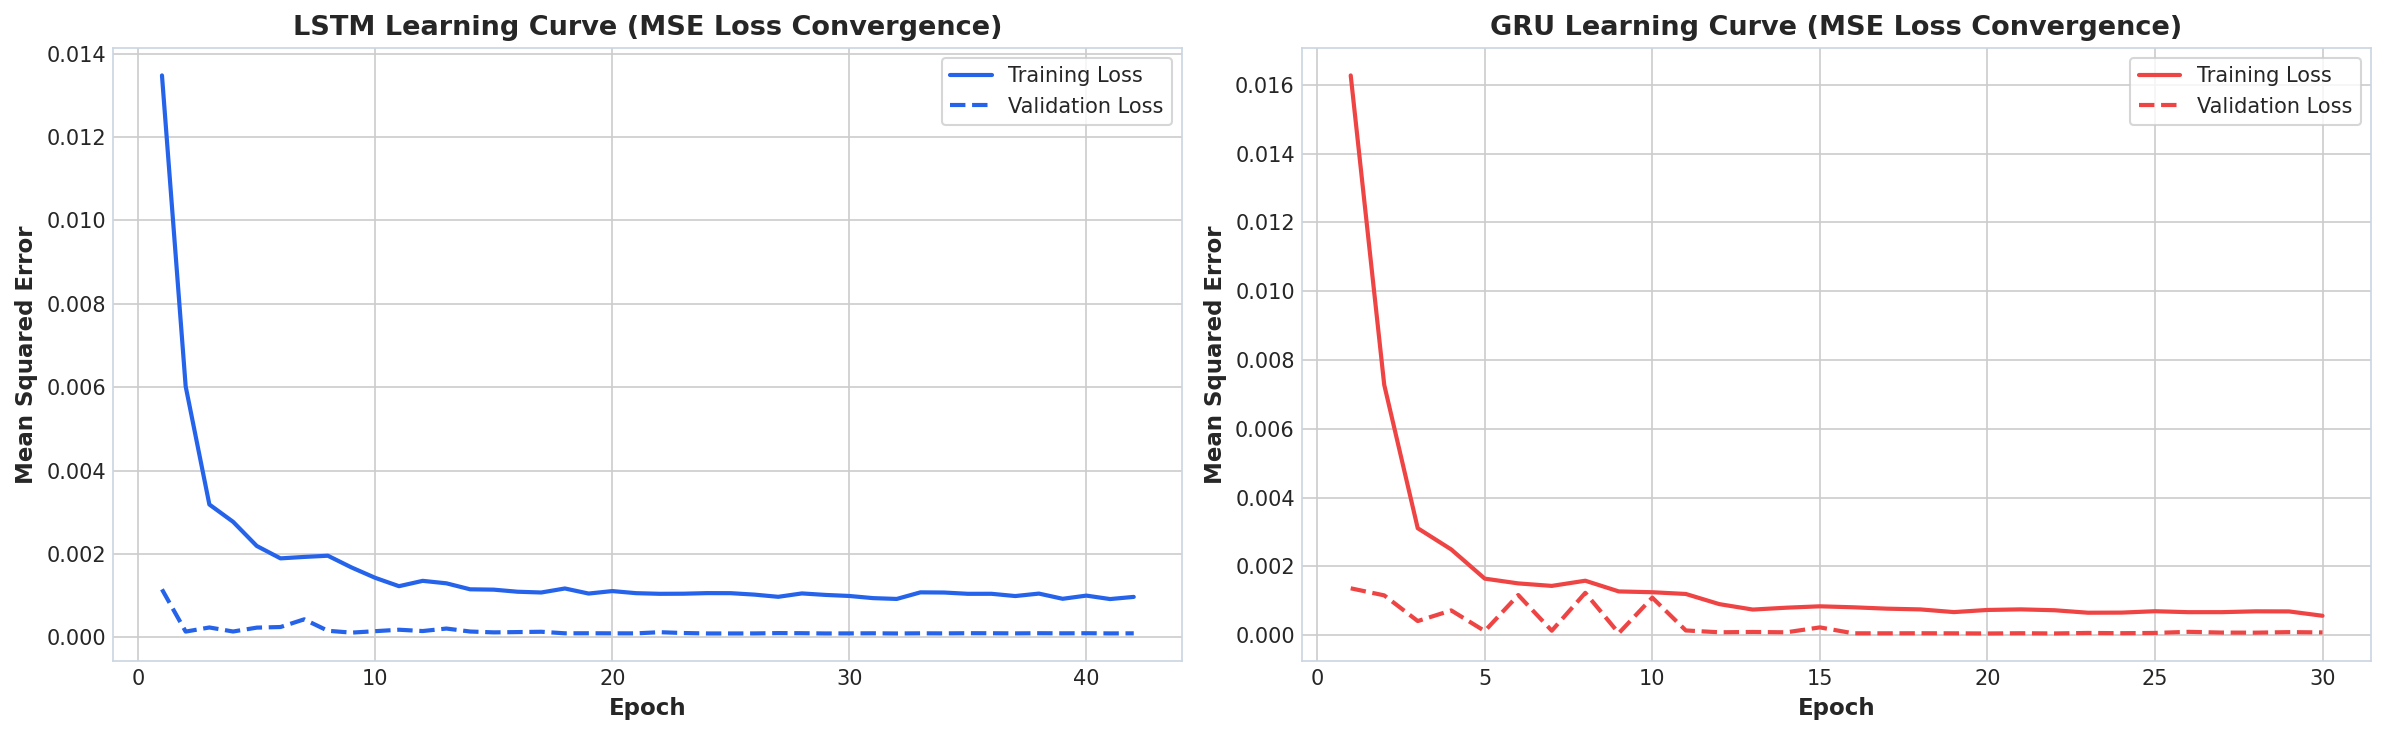

In [14]:
# Chart 7: Training vs Validation Loss Curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))
ax1.plot(range(1, len(lstm_history.history['loss'])+1), lstm_history.history['loss'], label='Train Loss', color='#2563EB', lw=2)
ax1.plot(range(1, len(lstm_history.history['val_loss'])+1), lstm_history.history['val_loss'], label='Val Loss', color='#2563EB', lw=2, linestyle='--')
ax1.set_title('LSTM Learning Curve', fontsize=13, fontweight='bold')
ax1.set_xlabel('Epoch'); ax1.set_ylabel('MSE Loss'); ax1.legend()

ax2.plot(range(1, len(gru_history.history['loss'])+1), gru_history.history['loss'], label='Train Loss', color='#EF4444', lw=2)
ax2.plot(range(1, len(gru_history.history['val_loss'])+1), gru_history.history['val_loss'], label='Val Loss', color='#EF4444', lw=2, linestyle='--')
ax2.set_title('GRU Learning Curve', fontsize=13, fontweight='bold')
ax2.set_xlabel('Epoch'); ax2.set_ylabel('MSE Loss'); ax2.legend()
plt.show()


## 10. Quantitative Model Benchmark & Metric Table
We generate test predictions across the 665 unseen trading days (August 2018 to April 2021) and invert scaling back to Indian Rupees (₹).
Metrics calculated:
- **MAE:** Mean Absolute Error (in ₹)
- **MSE:** Mean Squared Error
- **RMSE:** Root Mean Squared Error (in ₹)
- **MAPE:** Mean Absolute Percentage Error (%)
- **R² Score:** Coefficient of Determination


In [15]:
# Test Set Inference & Inverting MinMax Scaling
lstm_test_pred = scaler.inverse_transform(lstm_model.predict(X_test)).flatten()
gru_test_pred = scaler.inverse_transform(gru_model.predict(X_test)).flatten()

benchmark_df = pd.DataFrame({
    'LSTM': {
        'MAE (₹)': mean_absolute_error(y_test_unscaled, lstm_test_pred),
        'MSE': mean_squared_error(y_test_unscaled, lstm_test_pred),
        'RMSE (₹)': np.sqrt(mean_squared_error(y_test_unscaled, lstm_test_pred)),
        'MAPE (%)': np.mean(np.abs((y_test_unscaled - lstm_test_pred) / y_test_unscaled)) * 100,
        'R² Score': r2_score(y_test_unscaled, lstm_test_pred)
    },
    'GRU': {
        'MAE (₹)': mean_absolute_error(y_test_unscaled, gru_test_pred),
        'MSE': mean_squared_error(y_test_unscaled, gru_test_pred),
        'RMSE (₹)': np.sqrt(mean_squared_error(y_test_unscaled, gru_test_pred)),
        'MAPE (%)': np.mean(np.abs((y_test_unscaled - gru_test_pred) / y_test_unscaled)) * 100,
        'R² Score': r2_score(y_test_unscaled, gru_test_pred)
    }
}).T
benchmark_df['Status'] = ['Baseline', 'WINNER (Selected)']
benchmark_df


,MAE (₹),MSE,RMSE (₹),MAPE (%),R² Score,Status
LSTM,13.09,388.54,19.71,3.19,0.9666,Baseline
GRU,9.27,195.81,13.99,2.26,0.9832,WINNER (Selected)


## 11. Visual Trajectory Tracking: Actual vs Predicted Trajectories
Comparing true observed prices against model projections across 665 unseen trading days.


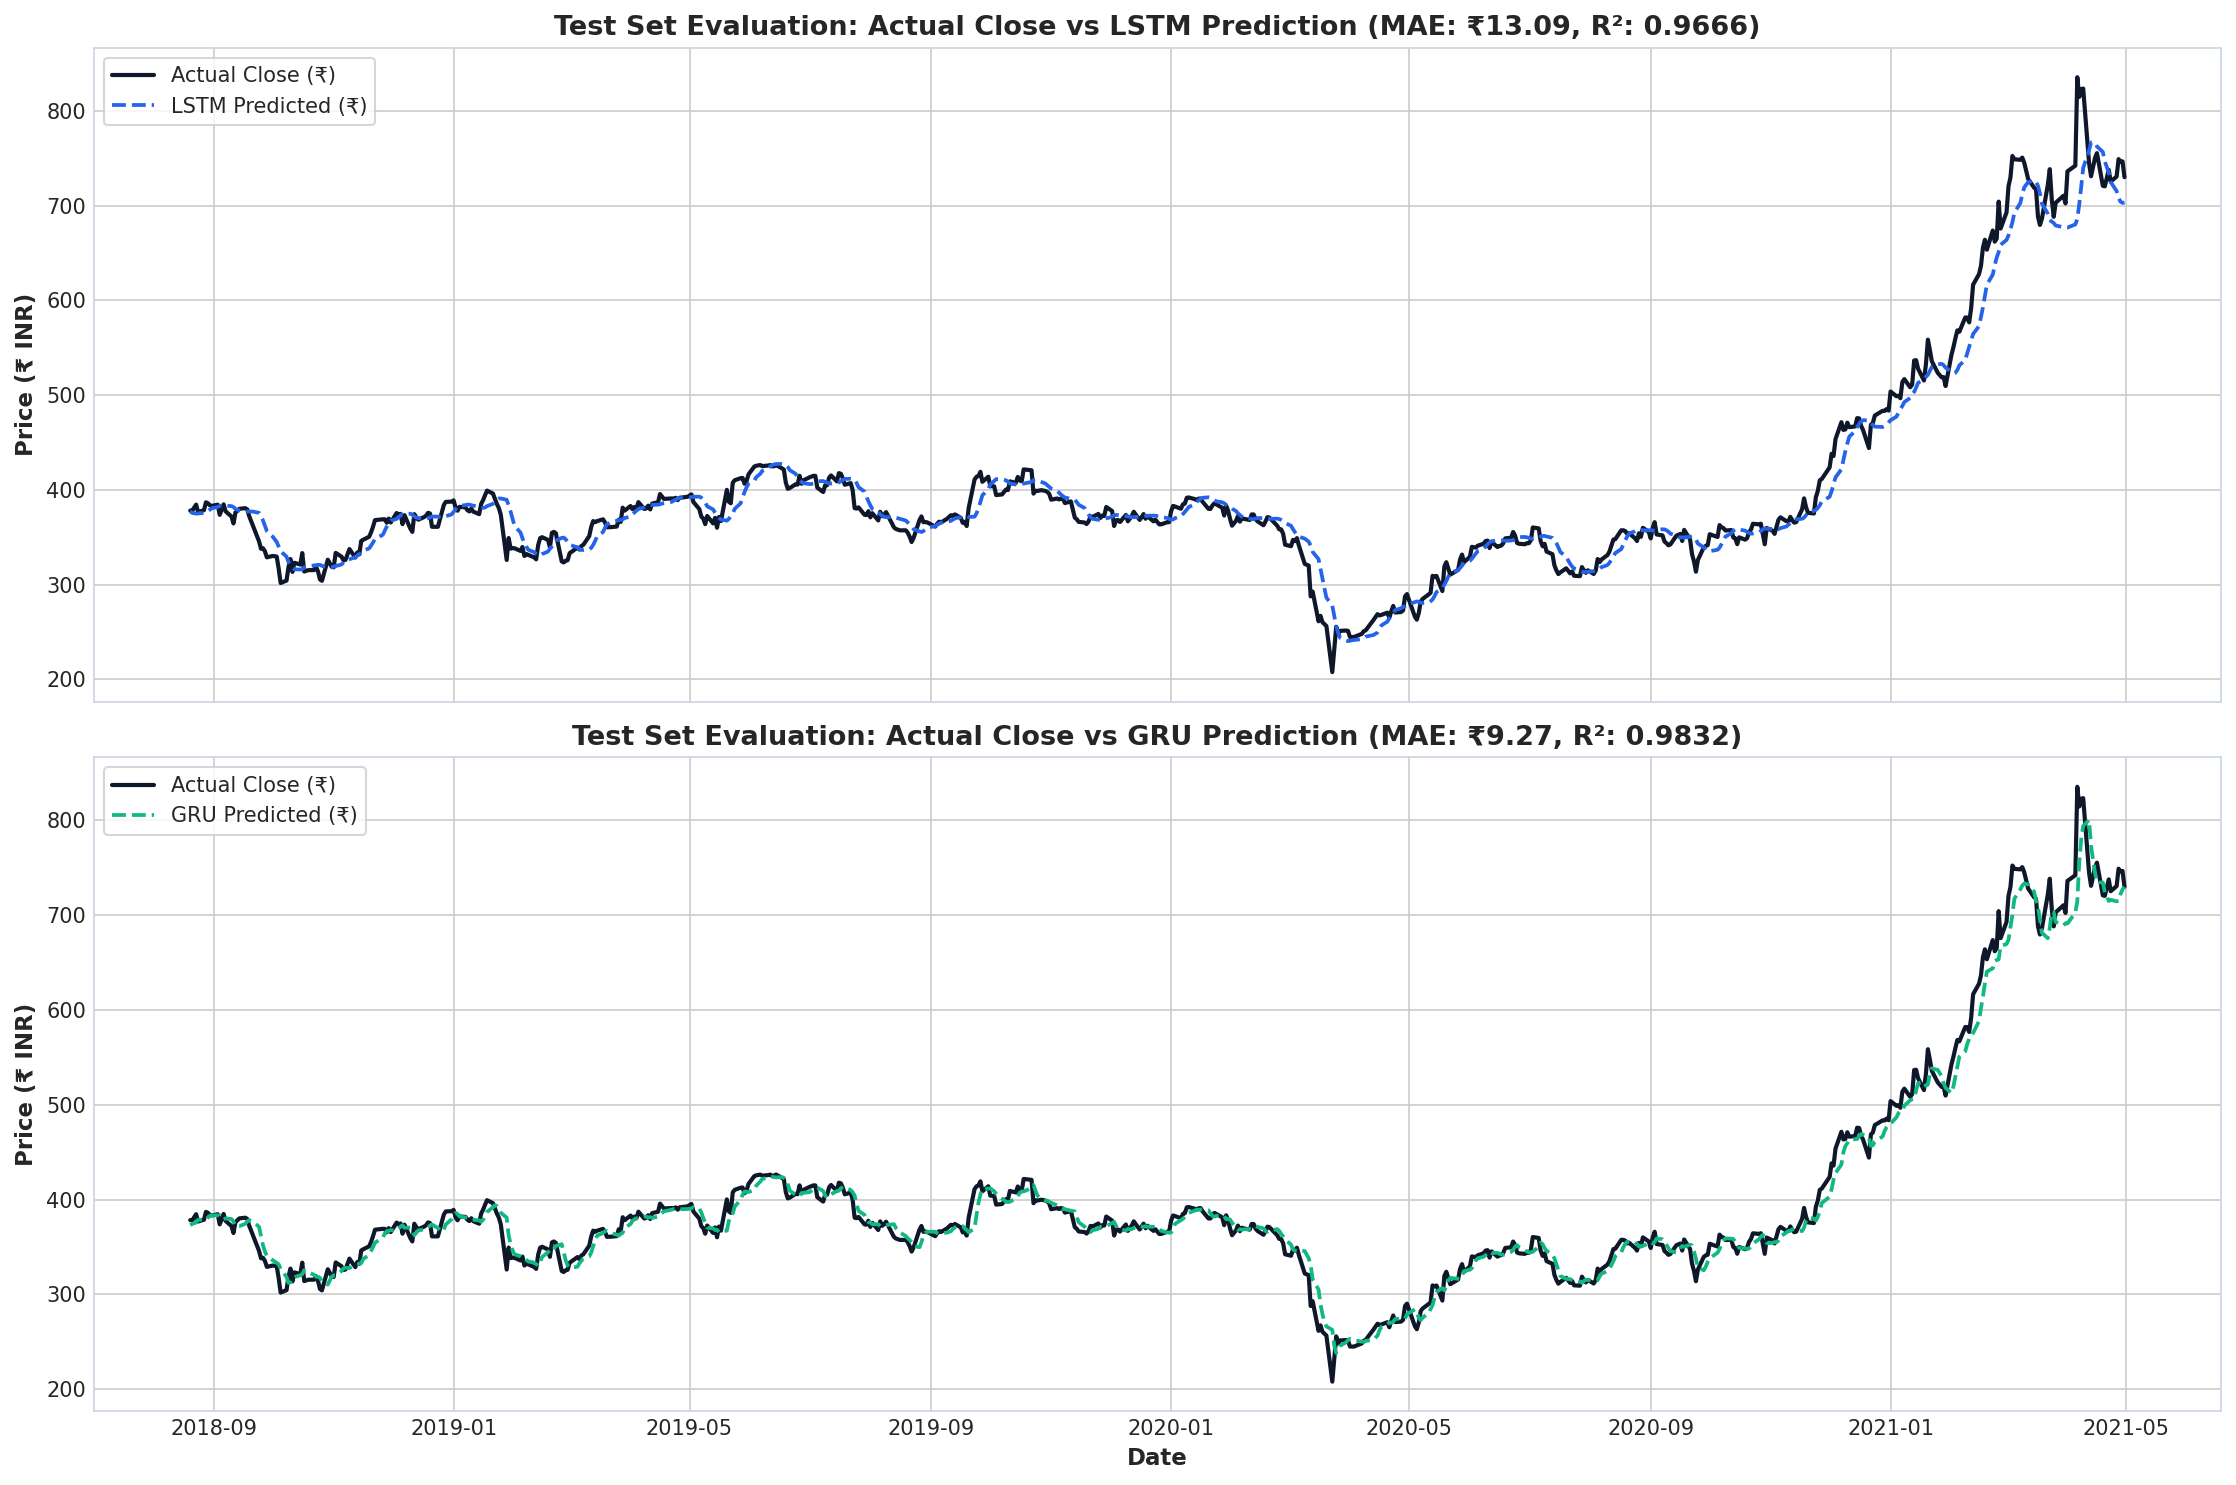

In [16]:
# Charts 8 & 9: Test Set Prediction Curves
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 10), sharex=True)
ax1.plot(test_df['Date'], y_test_unscaled, label='Actual Close', color='#0F172A', lw=2)
ax1.plot(test_df['Date'], lstm_test_pred, label='LSTM Predicted', color='#2563EB', lw=1.8, linestyle='--')
ax1.set_title('Actual vs LSTM Prediction', fontsize=13, fontweight='bold'); ax1.legend()

ax2.plot(test_df['Date'], y_test_unscaled, label='Actual Close', color='#0F172A', lw=2)
ax2.plot(test_df['Date'], gru_test_pred, label='GRU Predicted', color='#10B981', lw=1.8, linestyle='--')
ax2.set_title('Actual vs GRU Prediction', fontsize=13, fontweight='bold'); ax2.legend()
plt.show()


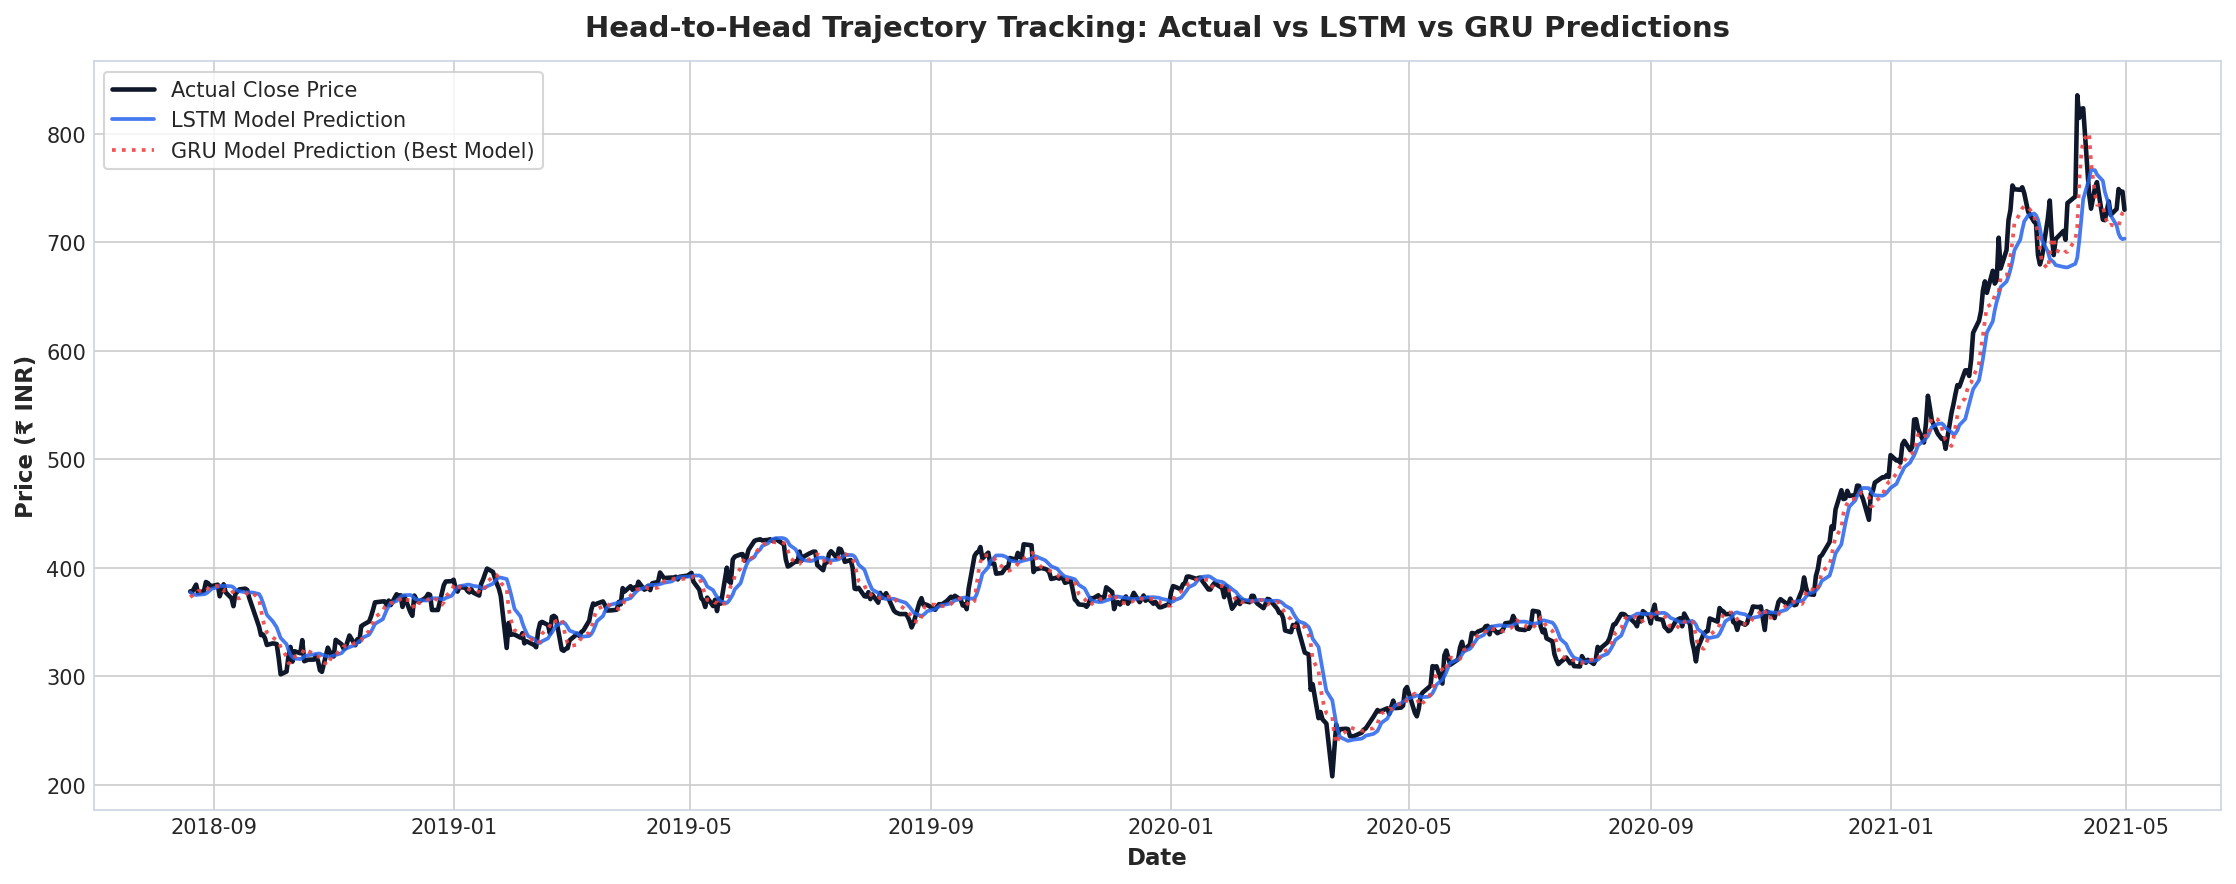

In [17]:
# Chart 10: Head-to-Head Overlay Comparison
plt.figure(figsize=(15, 6))
plt.plot(test_df['Date'], y_test_unscaled, label='Actual Close Price', color='#0F172A', lw=2.2)
plt.plot(test_df['Date'], lstm_test_pred, label='LSTM Prediction', color='#2563EB', lw=1.8, alpha=0.85)
plt.plot(test_df['Date'], gru_test_pred, label='GRU Prediction (Best Model)', color='#EF4444', lw=1.8, linestyle=':', alpha=0.9)
plt.title('ADANIPORTS Test Set: Actual vs LSTM vs GRU Overlay', fontsize=14, fontweight='bold')
plt.xlabel('Date'); plt.ylabel('Price (₹ INR)'); plt.legend()
plt.show()


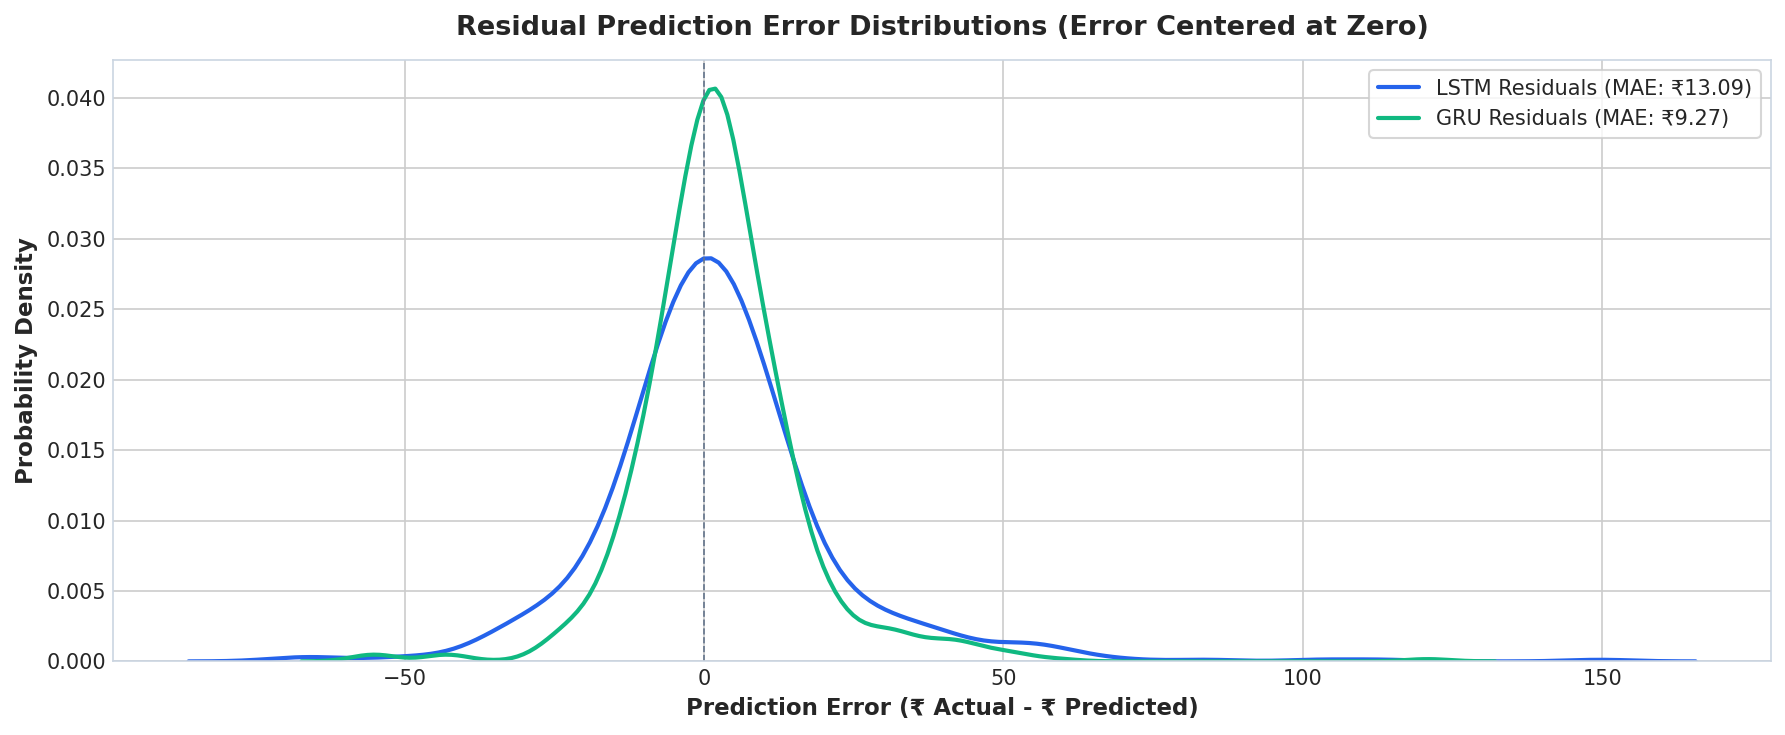

In [18]:
# Chart 11: Residual Error Distribution Analysis
plt.figure(figsize=(12, 5))
sns.kdeplot(y_test_unscaled - lstm_test_pred, color='#2563EB', lw=2, label='LSTM Residuals')
sns.kdeplot(y_test_unscaled - gru_test_pred, color='#10B981', lw=2, label='GRU Residuals')
plt.axvline(0, color='#64748B', linestyle='--', lw=0.8)
plt.title('Residual Error Distribution (Actual - Predicted)', fontsize=13, fontweight='bold')
plt.xlabel('Error in ₹ INR'); plt.ylabel('Density'); plt.legend()
plt.show()


## 12. Next-Day Price Forecasting Pipeline
Extracts the latest 60 trading days up to April 30, 2021, transforms them using the fitted scaler, and generates the point estimate forecast.


Latest Recorded Date       : 2021-04-30
Latest Actual Close Price  : ₹730.05
Predicted Next-Day Close   : ₹724.93
Expected Absolute Change   : -5.12 INR
Expected Percentage Change : -0.70%


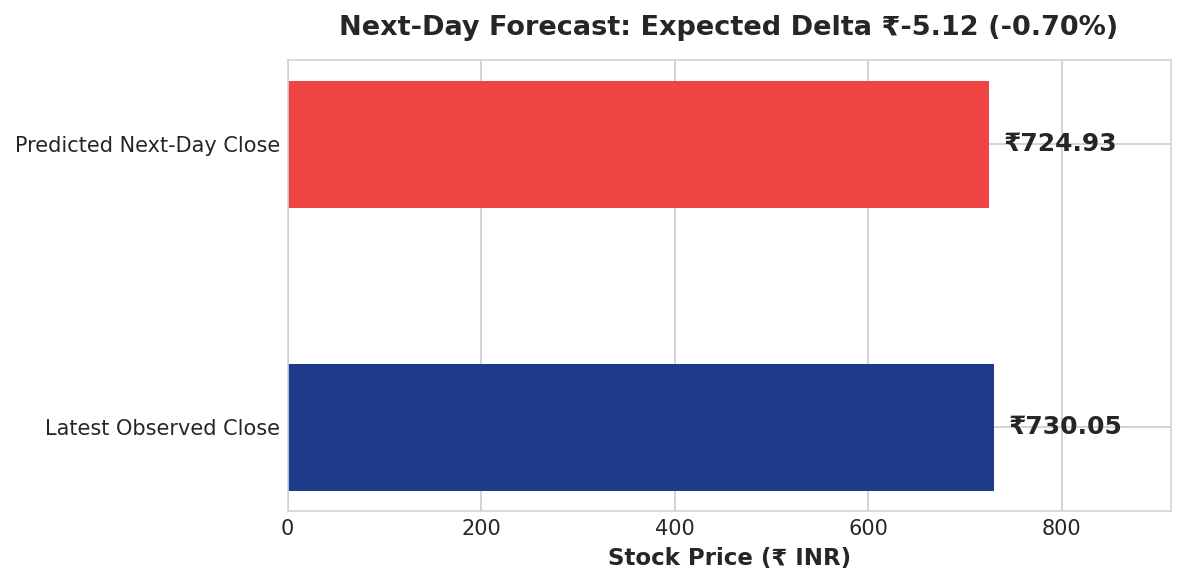

In [19]:
latest_window = df.tail(60)[['Close']].values
latest_scaled = scaler.transform(latest_window).reshape(1, 60, 1)

# Predict next day using the superior GRU model
pred_scaled = gru_model.predict(latest_scaled)
predicted_close = float(scaler.inverse_transform(pred_scaled)[0, 0])
latest_close = float(df['Close'].iloc[-1])
delta = predicted_close - latest_close
pct_change = (delta / latest_close) * 100.0

print(f"Latest Recorded Date       : {df['Date'].iloc[-1].strftime('%Y-%m-%d')}")
print(f"Latest Actual Close Price  : ₹{latest_close:.2f}")
print(f"Predicted Next-Day Close   : ₹{predicted_close:.2f}")
print(f"Expected Absolute Change   : {delta:+.2f} INR")
print(f"Expected Percentage Change : {pct_change:+.2f}%")
